# [Lab Session 2](otsu.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

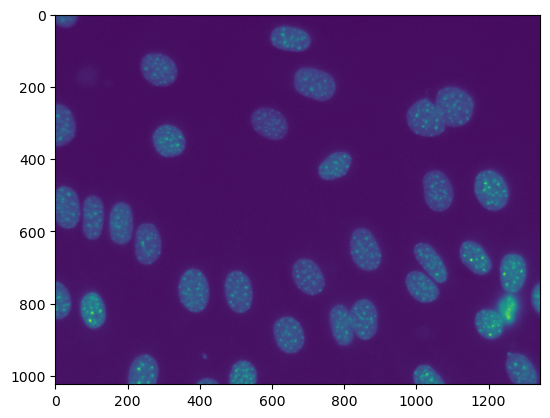

In [14]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')
plt.figure()
plt.imshow(imgf)

**[Task 1.2.]()** Quantify the image into 256 bins:

In [5]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [8]:
h = np.zeros(256)
for i in range(256):
    h[i] = np.sum(img8 == i)


Show the computed histogram:

<BarContainer object of 256 artists>

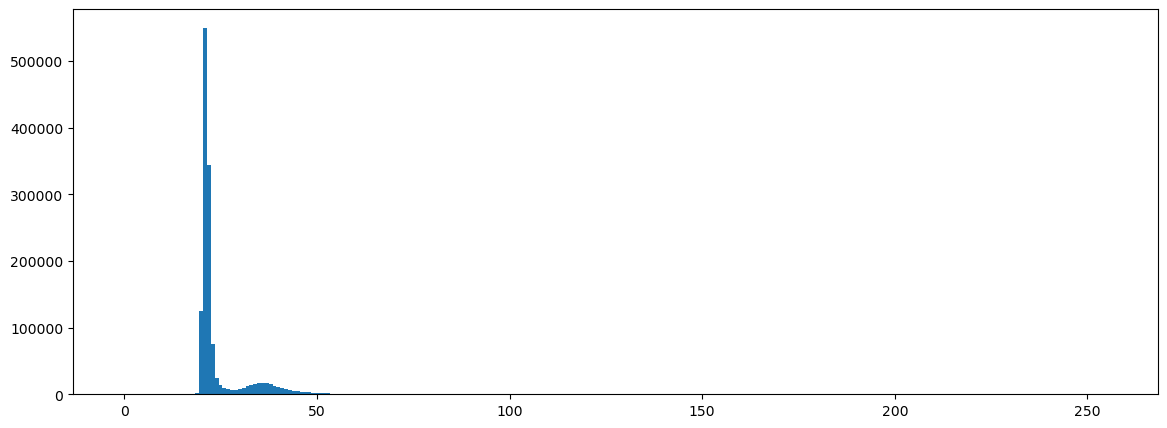

In [9]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [11]:
scores = np.full(255, np.inf)

for T in range(1, 256):
    class1 = img8[img8 < T]
    class2 = img8[img8 >= T]

    if class1.size == 0 or class2.size == 0:
        continue

    scores[T - 1] = (
        class1.size * np.var(class1)
        + class2.size * np.var(class2)
    )

T_opt = np.argmin(scores) + 1

print(T_opt)

31


**[Task 1.5.]()** Perform Otsu thresholding:

In [13]:
segmentation = img8 >= T_opt

**[Task 1.6.]()** Compute the Dice coefficient:

In [15]:
# ground truth
h = plt.imread("data/NIH3T3/gt/0.png")
h_bool = h > 0

dice = 2 * (segmentation & h_bool).sum() / (segmentation.sum() + h_bool.sum())

print(dice)

0.8943783223933183
